# Agglomerative Hierarchical Clustering

## Prerequisite

Student should know about:

+ Basic of Hierarchical Clustering

+ Basic of graph theory

## Learning Objective

After completing this chapter, students should be able to:

+ Identify _Agglomerative_ vs _Divisive_ Clustering

+ Explain at least three different types of _Cluster Linkage_

+ Explain _Ward's Criteria_


## Agglomerative Clustering


Agglomerative clustering is the most popular hierarchical clustering algorithm. It is a bottom up approach, so we start by singleton clusters then merge the clusters until a stopping condition or all data belongs to a single cluster. For simplicity, we are going to stop the algorithm only when all the data points belongs to a single cluster. The process of agglomerative clustering algorithm is clearly shown in the animation below.

<div align="center">
    <figure>


<p>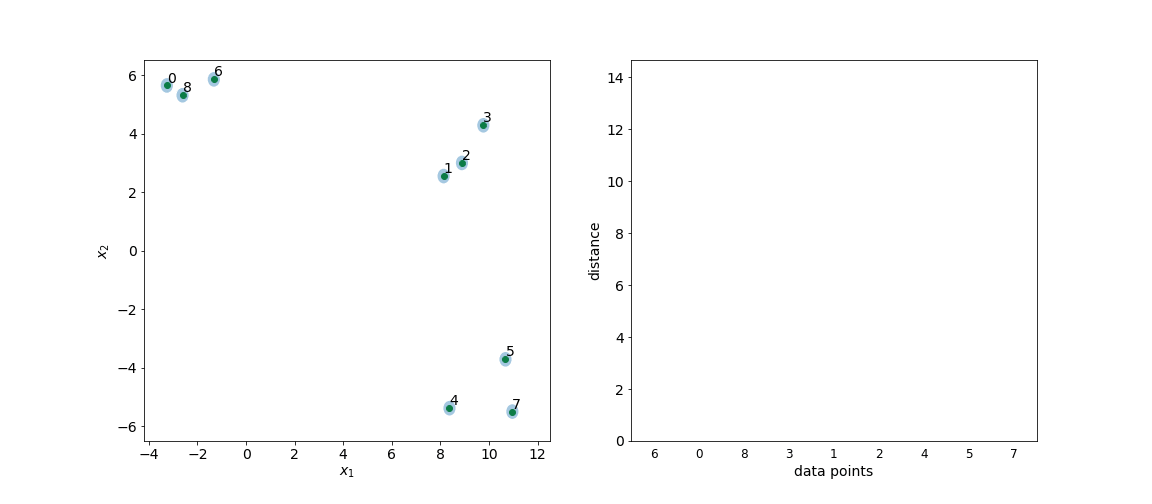</p>
        <figcaption>Figure 2: Agglomerative clustering on a toy dataset. (a) Scatter plot with highlighted clusters. (b) Agglomerative clustering shown in dendogram</figcaption>
    </figure>
</div>

The Figure 2(a) shows the iterative process where at each step two clusters are combined. The dendogram for the corresponding step in the Figure 2(a) is shown in the Figure(b).


### General Agglomerative Clustering Algorithm

Suppose we have a dataset given as $\mathcal x = \{x_1, \dots, x_n\}$. A general agglomerative clustering algorithm to partition this dataset is given below.

---
__ALGORITHM:__ General Agglomerative Clustering Algorithm

---
1. __Initialization:__

    a. Create an initial clustering $\mathcal C_0$ as,
$$
\mathcal A_0 = \{\mathcal C_i = \{x_i\}, i=1,\dots,n\}
$$

    b. Set time step $t = 0$

2. __REPEAT:__

    a. Increase the time step as, $t = t + 1$

    b. Calculate the proximity matrix for $\mathcal A_0$ (if required)

    c. Find a cluster $(\mathcal C_a, \mathcal C_b)$ from all the possible pairs of clusters $(\mathcal C_i, \mathcal C_j)$ in $\mathcal A_{t-1}$ using proximity matrix where,
$$
d(\mathcal C_a, \mathcal C_b) = \min_{i,j} D(\mathcal C_i, \mathcal C_j), \ \  i \neq j
$$

    Where $D(\cdot)$ is a dissimilarity or distance function.

    d. Create a new cluster $\mathcal C_k$ as,
$$
\mathcal C_k = \mathcal C_a \cup \mathcal C_b
$$

    e. Produce a new clustering $\mathcal A_t$ as,
$$
\mathcal A_t = (\mathcal A_{t-1} - \{\mathcal C_a, \mathcal C_b\}) \cup \{\mathcal C_k\}
$$

    __UNTIL:__ All data lie in a single cluster
---

In the above algorithm, all the steps are straight forward other than the dissimilarity function $d(\cdot)$ used when calculating the proximity matrix seems esoteric. The function $d(\cdot)$ calculates the distance between two data points, a data point and a cluster or two clusters. In the following section we are going go learn about various agglomerative clustering algorithms based on their different merge criterion.


### Agglomerative Clustering Algorithms

Firstly, we are going to learn about three algorithms based on the linkage between two clusters. The dissimilarity or distance between two clusters (which are represented as a set) is called the _linkage_. For two sets $\mathcal A$ and $\mathcal B$, the linkage given as $D(\mathcal A, \mathcal B)$ tells how much different are the points in those sets.

We are going to cover four types of linkage based algorithm given as,

1. Single Linkage Algorithm

2. Complete Linkage Algorithm

3. Average Linkage Algorithm

4. Centroid Linkage Algorithm


#### Single Linkage Algorithm


The single linkage algorithm, also known as MIN algorithm calculates the linkage as the distance between the nearest point in those two partitions. If we have two clusters $\mathcal A$ and $\mathcal B$, the single linkage between those clusters can be written as,
$$
D_{SL}(\mathcal A, \mathcal B) = \min \{d(x_i, x_j) \vert x_i \in \mathcal A, x_j \in \mathcal B\}
$$

The single linkage between two clusters whose data points are represented by different color is shown in the figure below.


<div align="center">
    <figure>


<p>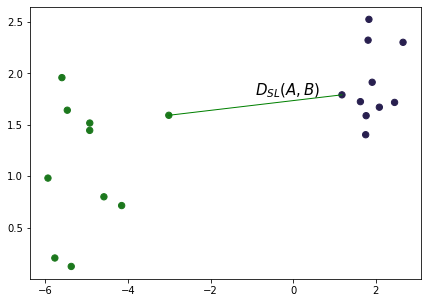</p>
        <figcaption>Figure 3: Single linkage between two clusters.</figcaption>
    </figure>
</div>

The shapes of clusters can be non-elliptic because single pair of close points is sufficient to merge the two clusters without the consideration of other points. Due to this property the cluster can also be spread out and not compact. This effect is called *chaining effect* because a cluster can get chained to a long spread out cluster. Similarly, it is sensitive to noise and outliers because two dissimilar clusters can get merged due to the presence of outlier or noise point in either of the cluster.

In terms of graph theory, if we start to link two clusters starting from a singleton cluster with joining or linking the cluster with shortest link, only a single link is sufficient to connect the points into a cluster; ergo, it is called the single linkage algorithm.


#### Complete Linkage Algorithm

The complete linkage algorithm also known as MAX or CLIQUE algorithm calculates the distance between two clusters as the distance between the farthest points in those clusters. The complete linkage between clusters $\mathcal A$ and $\mathcal B$ can be written as,
$$
D_{CL}(\mathcal A, \mathcal B) = \max \{d(x_i, x_j) \vert x_i \in \mathcal A, x_j \in \mathcal B\}
$$

The complete linkage for two cluster is shown in the figure below.

<div align="center">
    <figure>


<p>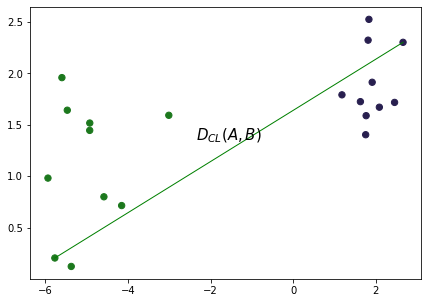</p>
        <figcaption>Figure 4: Complete linkage between two clusters.</figcaption>
    </figure>
</div>

Unlike single linkage algorithm, the shapes of cluster with complete linkage algorithm tend to be globular and does not suffer from the chaining effect. But the shape of cluster can be more compact and suffer from crowding. _MAX algorithm_ is less susceptible to noise and outliers but it can break a larger cluster into smaller ones.

This algorithm is called complete linkage because if we start from a singleton cluster and link the two closest point first; then, the group of points are not cluster until all the points are completely linked (connected to all others) or form a clique.


#### Average Linkage Algorithm

Average linkage algorithm calculates the average of distance between all the pairs of data points. The average linkage between two clusters $\mathcal A$ and $\mathcal B$ can be written as,
$$
D_{AL} = \frac{1}{\vert\mathcal A\vert \vert\mathcal B\vert} \sum\{d(x_i, x_j) \vert x_i \in \mathcal A, x_j \in \mathcal B\}
$$

Where $\vert \mathcal A\vert$ and $\vert \mathcal B\vert$ denotes the cardinality of partition $\mathcal A$ and $\mathcal B$ respectively.

The dissimilarity between points required for average linkage is shown in the figure below.

<div align="center">
    <figure>


<p>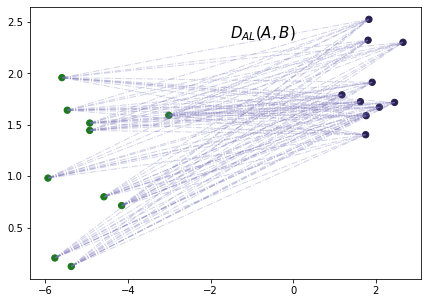</p>
        <figcaption>Figure 5: Average linkage between two clusters.</figcaption>
    </figure>
</div>

The average linkage tries to find the balance between the single and complete linkage algorithm. Average linkage algorithm is less suseptible to noise or outliers. It favors the globular or circular clusters rather than elongated non-elliptical clusters.

One of major problem with average linkage is that the result of this clustering is highly dependent upon the similarity measure and the result may change if we apply a simple linear transformation to that distance function. This can be a problem since we are not always sure which distance function to use. The single and complete link on the other hand does not suffer from this problem.


#### Centroid Linkage Algorithm


The centroid linkage algorithm a.k.a unweighted pair group method centroid (UPGMC) is a hierarchical clustering algorithm where two clusters are merged together based on the distance between their centroids. Let $\mathcal A$ be a cluster with data points $\{x_1, \dots, x_n\}$, then its centroid, as you have already learnt to calculate in _K_-Means algorithm, is defined as,
$$
m_{\mathcal A}  = \frac{1}{n} \sum_{i=1}^{n} x_i
$$

Now, the distance between two clusters, say $\mathcal A$ and $\mathcal B$, is defined as,
$$
D_{CN} = d(m_{\mathcal A}, m_{\mathcal B})
$$

Where $m_{\mathcal A}$ and $m_{\mathcal B}$ are the centroid of the cluster $\mathcal A$ and $\mathcal B$ respectively. The distance or dissimilarity function between two points represented by $d(\cdot)$ can be any distance function, but we will euclidian distance for simplicity.

The centroid linkage for two clusters is clearly shown in the figure below.

<div align="center">
    <figure>


<p>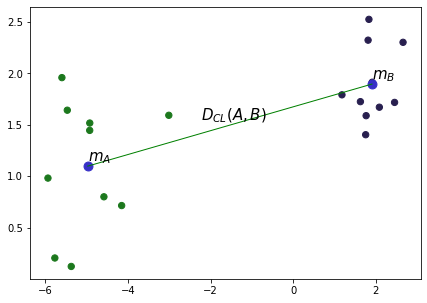</p>
        <figcaption>Figure 6: Centroid linkage between two clusters.</figcaption>
    </figure>
</div>


Until now, we have seen four types of merging criterion based on the distance between the two clusters. Calculating the distance is not the only approach for merging two clusters. The following algorithm called _Ward's method_ depends on the different criteria and it is described in details below.


#### Ward's method

Ward's method or criterion measures the dissimilarity between two clusters based on the change in sum of square error (SSE) before and after the merge of two clusters. You have already studied about the SSE in the _K_-Means section where our objective was to minimize the total SSE. Also, you saw that increasing the value of _K_ always decreases the SSE. In agglomerative clustering we are trying to merge smaller cluster to form a bigger one which will always increase the SSE. Hence, with _Ward's method_, we will merge those two cluster where the increase in SSE is least.

If $c_{\mathcal A}$ and $c_{\mathcal B}$ are centroid of clusters $\mathcal A$ and $\mathcal B$, then the ward's distance can be written as,
$$
D_W(\mathcal A, \mathcal B) = \frac{n_{\mathcal A} n_{\mathcal B}}{n_{\mathcal A} + n_{\mathcal B}} \Vert c_{\mathcal A} - c_{\mathcal B}\Vert^2
$$

<!-- 
There are many varients of ward's dissimilarity measure but here we present the original formula presented by __J.H.  Ward__ in 1963. -->

The dissimilarity with Ward's method for two clusters $\mathcal A$ and $\mathcal B$ can also be written in terms of data points as,
$$
D_W(\mathcal A, \mathcal B) = \frac{n_{\mathcal A} n_{\mathcal B}}{n_{\mathcal A} + n_{\mathcal B}}\left[\frac{2}{n_{\mathcal A}n_{\mathcal B}} \sum\{d^2(x_i, x_j) \vert x_i\in\mathcal A, x_j\in\mathcal B\} - \frac{1}{n_{\mathcal A}^2} \sum\{d^2(x_i, x_j) \vert x_i\in\mathcal A, x_j\in\mathcal B\} - \frac{1}{n_{\mathcal B}^2} \sum\{d^2(x_i, x_j) \vert x_i\in\mathcal A, x_j\in\mathcal B\}\right]
$$

Where $n_{\mathcal A}$ and $n_{\mathcal B}$ are cardinality of cluster $\mathcal A$ and $\mathcal B$ respectively.


### Lance-Williams Dissimilarity Update Formula

Lance-Williams formula incorporates all the hierarchical methods we have studied so far in a single formula. If the cluster $C_b$ is formed by combining two clusters $C_i$ and $C_j$, the distance of $C_b$ with another cluster $C_a$ should be updated with the Lance-Williams dissimilarity update formula as,
$$
D(C_a, (C_i, C_j)) = \alpha_i D(C_a, C_i) + \alpha_j D(C_a, C_j) + \beta D(C_i, C_j) + \gamma \vert D(C_a, C_i) - D(C_a, C_j)\vert
$$

All the proximity formula we discussed above can be derived from this equation with different values of coefficients $\alpha_i, \alpha_j, \beta$ and $\gamma$. The table for different algorithms and their corrosponding coefficient value is given in the table below:


| Clustering Algorithm    |   $\alpha_1$    | $\alpha_2$   |     $\beta$   |    $\gamma$ |
|------    |------    |------    |------    |------    |
| Single Linkage | $1/2$ | $1/2$ | $0$ | $-1/2$ |
| Complete Linkage  | $1/2$ | $1/2$ | $0$ | $1/2$ |
| Average Linkage | $\frac{n_i}{n_i + n_j}$ | $\frac{n_j}{n_i + n_j}$ | $0$ | $0$ |
| Centroid Linkage | $\frac{n_i}{n_i + n_j}$ | $\frac{n_i}{n_i + n_j}$ | $\frac{n_i}{n_i + n_j}$ | $0$ |
| Ward's Method  | $\frac{n_i + n_a}{n_i + n_j + n_a}$ | $\frac{n_j + n_a}{n_i + n_j + n_a}$ | $\frac{-n_a}{n_i + n_j + n_a}$ | $0$ |



### Comparision of the Algorithms

Here we present to you the working of those four algorithms for different datasets.

<div align="center">
    <figure>


<p>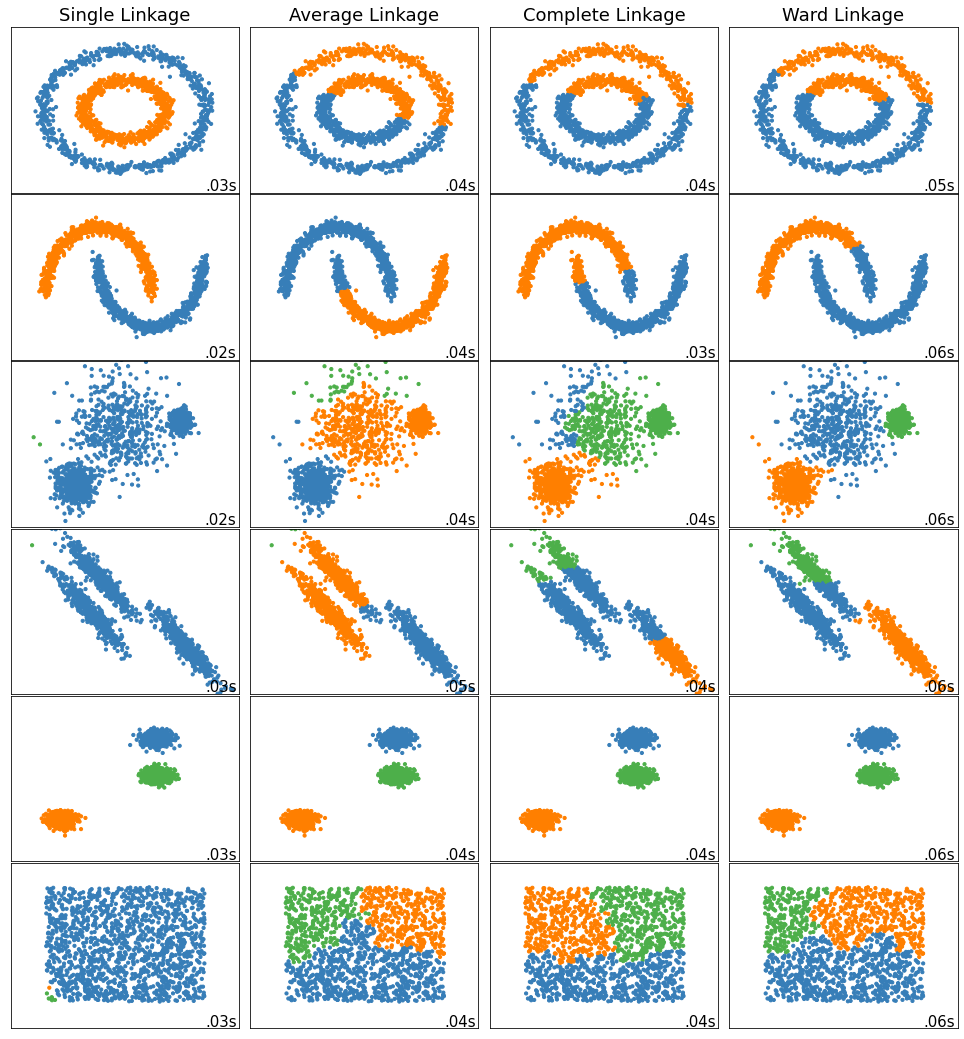</p>
        <figcaption>Figure 7: Clustering Algorithms on different types of datasets.</figcaption>
    </figure>
</div>


## Key Takeaways

+ Agglomerative clustering buildup the dendogram from bottom up approach which is opposite of divisive.

+ Linkage methods like single, complete, average, centroid are used to find the distance between two clusters (set of data points)

+ Ward's method is similar to _K_-Means in the sense that it tries to minimize the SSE the most when merging two clusters


## References

+ __Algorithms for Clustering Data__ _by Anil K. Jain and Richard C. Dubes_

    Look into the chapter 3 : Clustering methods and algorithms

+ A Comparative Study of Divisive and AgglomerativeHierarchical Clustering Algorithms by _Maurice Roux_
    
    https://hal.archives-ouvertes.fr/hal-02085844/document
